* Number of samples = 29998
* Maximum frequency = 149989999833.32224 Hz
* Frequency resolution = 5000166.677778519 Hz
* Number of samples = 15000
* Maximum time = 1.0000000011112591e-07 s
* Time resolution = 6.6671111481516044e-12 s
* Number of samples = 14998
* Maximum frequency = 74989999583.2889 Hz
* Frequency resolution = 5000333.372227038 Hz
* Number of samples = 7500
* Maximum time = 1.000000005556889e-07 s
* Time resolution = 1.3335111422281492e-11 s


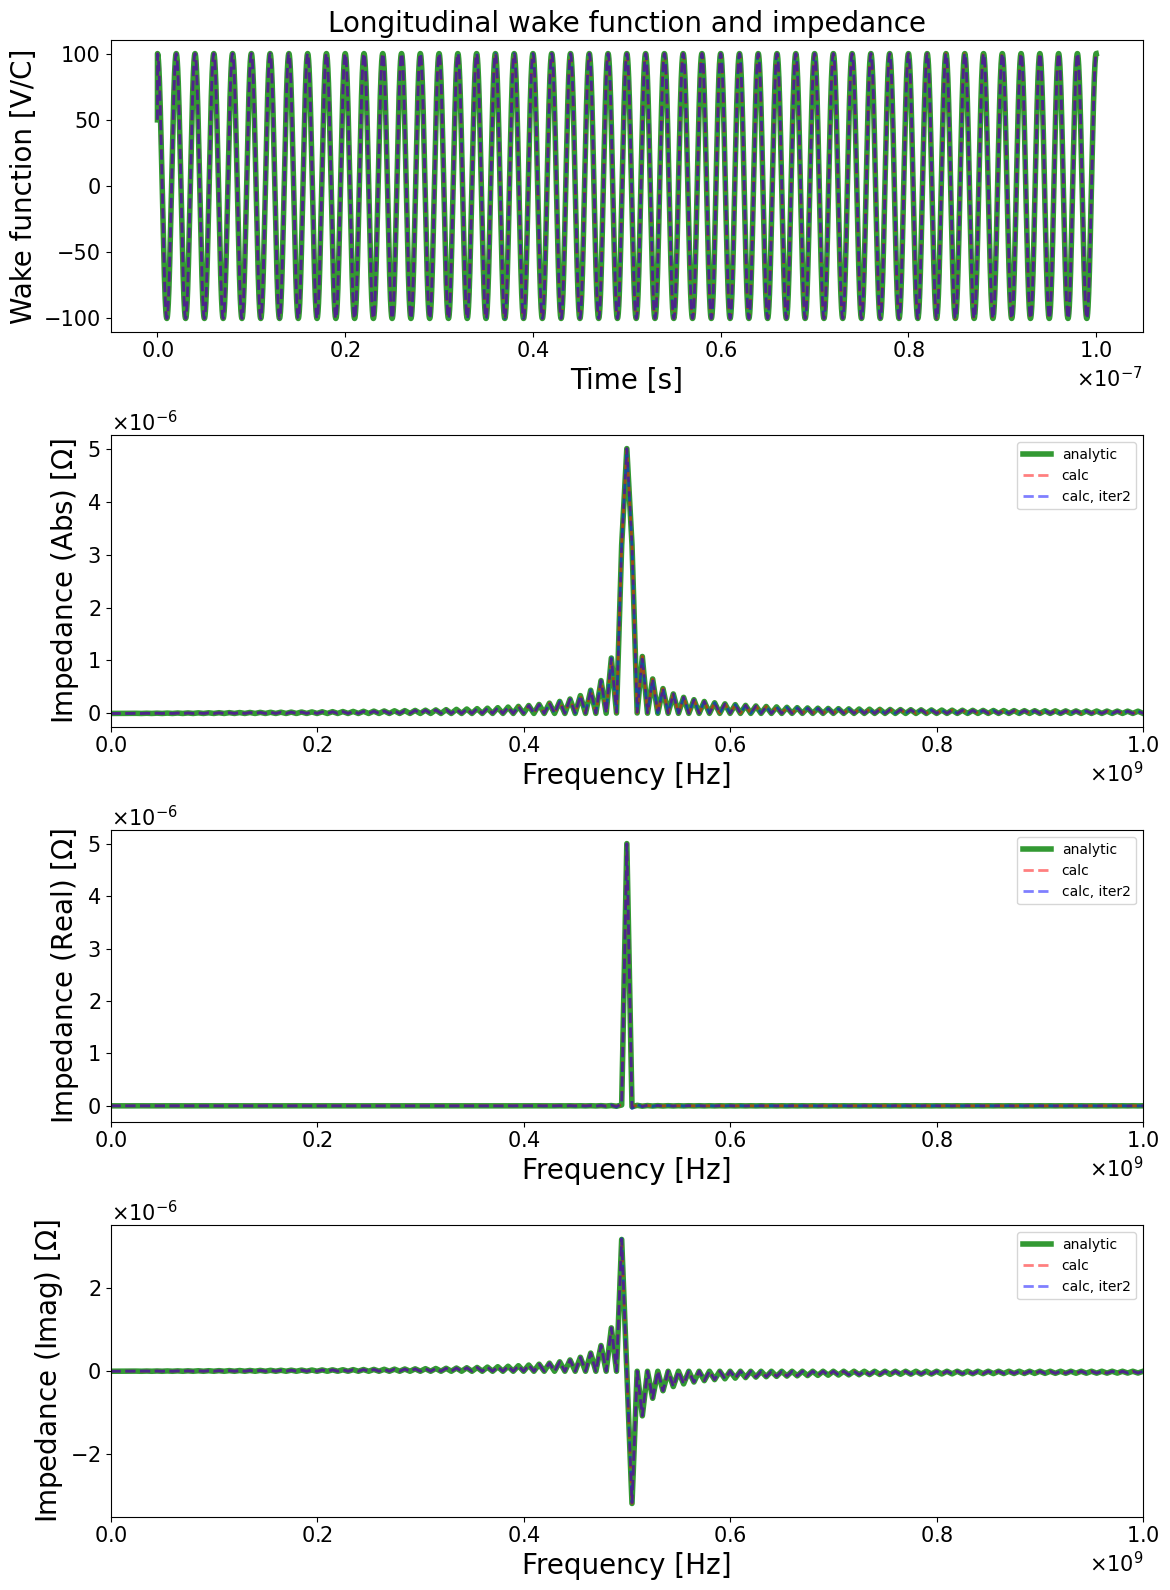

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
from scipy.constants import c as c_light
from scipy.fft import ihfft


def calc_long_Z_from_long_wake(
    wake, s=None, t=None, fmax=None, samples=None, verbose=True
):
    """
    Calculate longitudinal impedance from longitudinal wake function using FFT.

    Parameters
    ----------
    wake : array_like or list
        Wake function or [t, wake] list.
    s : ndarray, optional
        Distance array [m].
    t : ndarray, optional
        Time array [s].
    verbose : bool, optional
        If True, print information.

    Returns
    -------
    f : ndarray
        Frequency array [Hz].
    Z : ndarray
        Impedance array [Ohm].
    """

    if type(wake) is list:
        t = wake[0]
        wake = wake[1]
    if s is not None:
        t = s / c_light
    elif s is None and t is None:
        raise AttributeError(
            'Provide time or distance data through parameter "t" [s] or "s" [m]'
        )

    dt = np.mean(np.diff(t))

    if fmax is not None:
        aux = np.arange(t.min(), t.max(), 1 / fmax / 2)
        wake = np.interp(aux, t, wake)
        dt = np.mean(np.diff(aux))
        del aux
    else:
        fmax = 1 / dt

    # Obtain DFTs
    if samples is not None:
        Nf = 2 * samples
        Wfft = np.fft.fft(wake, n=Nf) * dt
    else:
        Nt = len(t)
        Nf = 4 * ((Nt + 1) // 2 - 1)
        Wfft = np.fft.fft(wake, n=Nf) * dt

    ffft = np.fft.fftfreq(Nf, dt)

    # Mask invalid frequencies
    mask = np.logical_and(ffft >= 0, ffft < fmax)
    Z = Wfft[mask]
    f = ffft[mask]

    if verbose:
        print(f"* Number of samples = {len(f)}")
        print(f"* Maximum frequency = {f.max()} Hz")
        print(f"* Frequency resolution = {np.mean(f[1:] - f[:-1])} Hz")

    return [f, Z]


def calc_long_wake_from_long_Z(impedance, f=None, verbose=True):
    """
    Calculate longitudinal wake function from longitudinal impedance using inverse FFT.

    Parameters
    ----------
    impedance : array_like or list
        Impedance or [f, Z] list.
    f : ndarray, optional
        Frequency array.
    verbose : bool, optional
        If True, print information.

    Returns
    -------
    t : ndarray
        Time array [s].
    wake : ndarray
        Wake function [V/C].
    """

    if type(impedance) is list:
        f = impedance[0]
        Z = impedance[1]
    elif f is None:
        raise AttributeError('Provide frequency data through parameter "f"')
    else:
        Z = impedance

    df = np.mean(np.diff(f))
    fmax = np.max(f)
    dt = 1 / (fmax)

    Nf = len(f)
    Nt = Nf // 2 + 1
    t = np.arange(Nt) * dt

    # Since the wake function is real, the longitudinal impedance satisfies
    # Hermitian symmetry, Z*(f) = Z(-f).
    # As a consequence, the inverse Fourier transform can be reduced
    # to a cosine transform involving only the real part of the impedance.
    # This Hermitian (cosine) reduction introduces an additional factor of four
    # compared to the full complex IFFT.
    # See Eqs. (2.72) and (2.92) in A. W. Chao,
    # "Physics of Collective Beam Instabilities in High Energy Accelerators".
    wake = np.real(ihfft(Z.real, norm="forward")) * 4 * df

    # IHFFT does not automatically apply the half-weighting of the boundary points
    # required by the discrete version of the fundamental theorem of beam loading.
    # Both the first and the last samples must therefore be scaled by 1/2.
    wake[[0, -1]] *= 0.5

    if verbose:
        print(f"* Number of samples = {len(t)}")
        print(f"* Maximum time = {t.max()} s")
        print(f"* Time resolution = {np.mean(t[1:] - t[:-1])} s")

    return [t, wake]


# Generate the input wake function
fr = 0.5e9
A = 100
Nsamples = 30000
t = np.linspace(0, 100 * 1e-9, Nsamples)
wake = A * np.cos(2 * np.pi * fr * t)

# Apply the fundamental theorem of beam loading
# for the longitudinal wake function
wake[0] *= 0.5

# Calculate impedances and wake funtions iteratively
f, Z = calc_long_Z_from_long_wake([t, wake])
tt, wwake = calc_long_wake_from_long_Z([f, Z])
ff, Zz = calc_long_Z_from_long_wake([tt, wwake])
ttt, wwwake = calc_long_wake_from_long_Z([ff, Zz])

# Calculate the analytical impedance
dt = np.mean(np.diff(t))
Nt = len(t)  # Default
Z_analytical = analytic_impedance_from_cosine_wake(f, fr, A, Nt * dt)

# Plot results
plt.rc("xtick", labelsize=15)
plt.rc("ytick", labelsize=15)

fig, (ax1, ax2, ax3, ax4) = plt.subplots(4, 1, figsize=(11.8, 16.0))
ax1.set_title("Longitudinal wake function and impedance", size="20")
ax1.plot(t, wake, "-g", alpha=0.8, label="analytic", linewidth="4")
ax1.plot(tt, wwake, "--r", alpha=0.5, label="calc", linewidth="2")
ax1.plot(ttt, wwwake, "--b", alpha=0.5, label="calc, iter2", linewidth="2")
ax1.set_xlabel("Time [s]", fontsize=20)
ax1.set_ylabel("Wake function [V/C]", fontsize=20)
x_formatter1 = ScalarFormatter(useMathText=True)
x_formatter1.set_powerlimits((-7, -7))
ax1.xaxis.set_major_formatter(x_formatter1)

ax2.plot(f, np.abs(Z_analytical), "-g", alpha=0.8, label="analytic", linewidth="4")
ax2.plot(f, np.abs(Z), "--r", alpha=0.5, label="calc", linewidth="2")
ax2.plot(ff, np.abs(Zz), "--b", alpha=0.5, label="calc, iter2", linewidth="2")
ax2.set_xlabel("Frequency [Hz]", fontsize=20)
ax2.set_ylabel(r"Impedance (Abs) [$\Omega$]", fontsize=20)
x_formatter2 = ScalarFormatter(useMathText=True)
x_formatter2.set_powerlimits((9, 9))
ax2.xaxis.set_major_formatter(x_formatter2)
y_formatter = ScalarFormatter(useMathText=True)
y_formatter.set_powerlimits((-6, -6))
ax2.yaxis.set_major_formatter(y_formatter)
ax2.set_xlim([0, 1e9])
ax2.legend()

ax3.plot(f, np.real(Z_analytical), "-g", alpha=0.8, label="analytic", linewidth="4")
ax3.plot(f, np.real(Z), "--r", alpha=0.5, label="calc", linewidth="2")
ax3.plot(ff, np.real(Zz), "--b", alpha=0.5, label="calc, iter2", linewidth="2")
ax3.set_xlabel("Frequency [Hz]", fontsize=20)
ax3.set_ylabel(r"Impedance (Real) [$\Omega$]", fontsize=20)
ax3.xaxis.set_major_formatter(x_formatter2)
ax3.yaxis.set_major_formatter(y_formatter)
ax3.set_xlim([0, 1e9])
ax3.legend()

ax4.plot(f, np.imag(Z_analytical), "-g", alpha=0.8, label="analytic", linewidth="4")
ax4.plot(f, np.imag(Z), "--r", alpha=0.5, label="calc", linewidth="2")
ax4.plot(ff, np.imag(Zz), "--b", alpha=0.5, label="calc, iter2", linewidth="2")
ax4.set_xlabel("Frequency [Hz]", fontsize=20)
ax4.set_ylabel(r"Impedance (Imag) [$\Omega$]", fontsize=20)
ax4.xaxis.set_major_formatter(x_formatter2)
ax4.yaxis.set_major_formatter(y_formatter)
ax4.set_xlim([0, 1e9])
ax4.legend()

fig.tight_layout()
plt.show()